In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import umap
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import ee
import os

In [17]:
sns.set_theme(style="darkgrid")

index = pd.read_parquet('../data/index.parquet')
completed = index[index['status'] == 'complete']

dfs = []
for _, row in completed.iterrows():
    path = os.path.join('..', row['output_path'])
    if os.path.exists(path):
        dfs.append(pd.read_parquet(path))
    else:
        print(f"Missing: {path}")

df = pd.concat(dfs, ignore_index=True)
print(f"Loaded {len(dfs)} regions, {len(df)} total samples")

Loaded 844 regions, 7628243 total samples


In [18]:
df_clean = df.dropna(subset=['label'])
print(f"Points after dropping nulls: {len(df_clean)}")
print(df_clean['label_name'].value_counts())

Points after dropping nulls: 7628243
label_name
Tree cover                2657382
Cropland                  2184637
Grassland                 1698725
Moss and lichen            317527
Bare/sparse vegetation     264838
Permanent water bodies     239246
Mangroves                   67942
Snow and ice                61614
Built-up                    56448
Shrubland                   44226
Herbaceous wetland          35658
Name: count, dtype: int64


In [19]:
min_count = df_clean['label'].value_counts().min()
df_balanced = df_clean.groupby('label').sample(n=min_count, random_state=42)

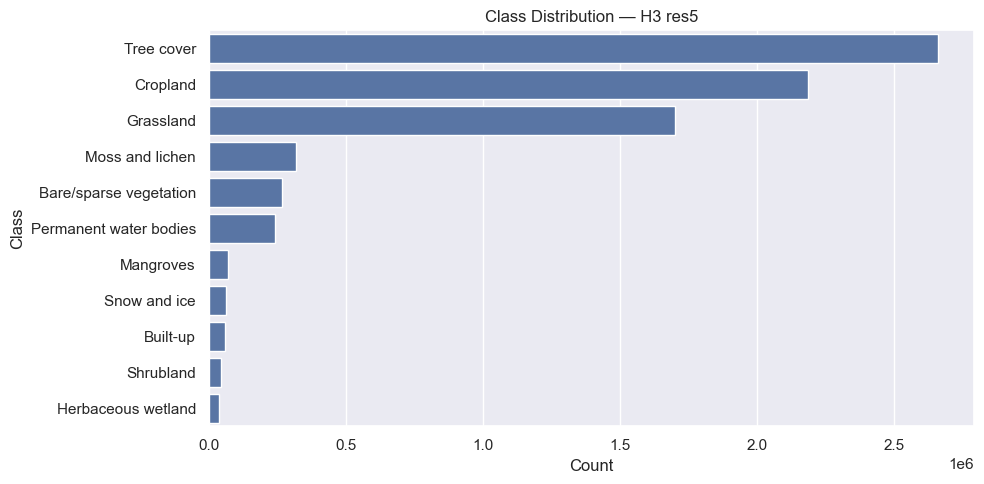

In [20]:
plt.figure(figsize=(10, 5))
order = df['label_name'].value_counts().index
sns.countplot(data=df, y='label_name', order=order)
plt.xlabel('Count')
plt.ylabel('Class')
plt.title('Class Distribution — H3 res5')
plt.tight_layout()
plt.show()

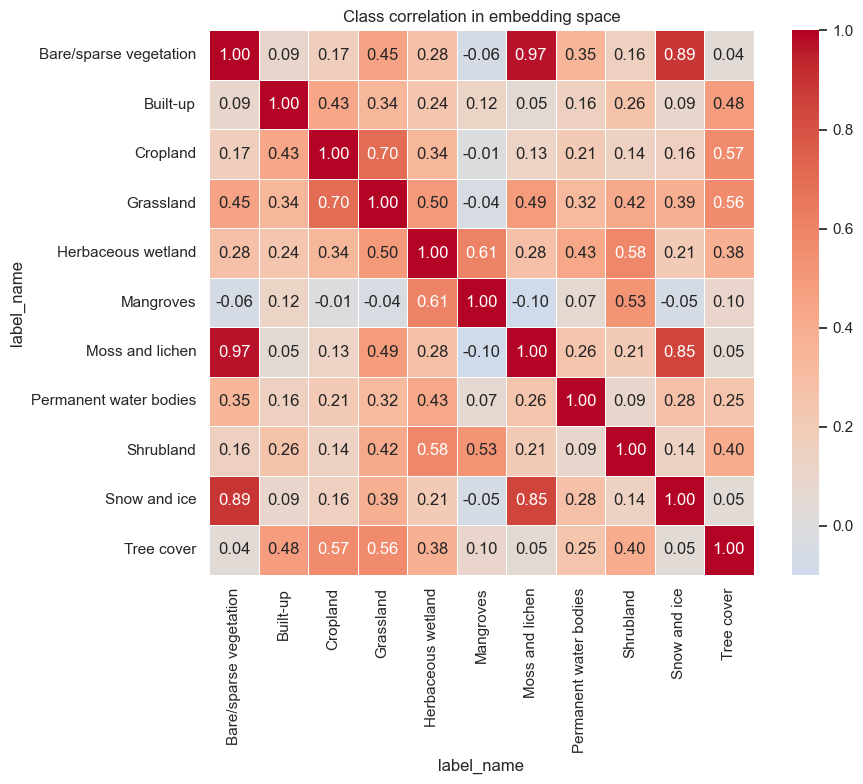

In [31]:
embedding_cols = [c for c in df.columns if c.startswith('A')]

class_means = df.groupby('label_name')[embedding_cols].mean()

corr = class_means.T.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Class correlation in embedding space')
plt.tight_layout()
plt.show()

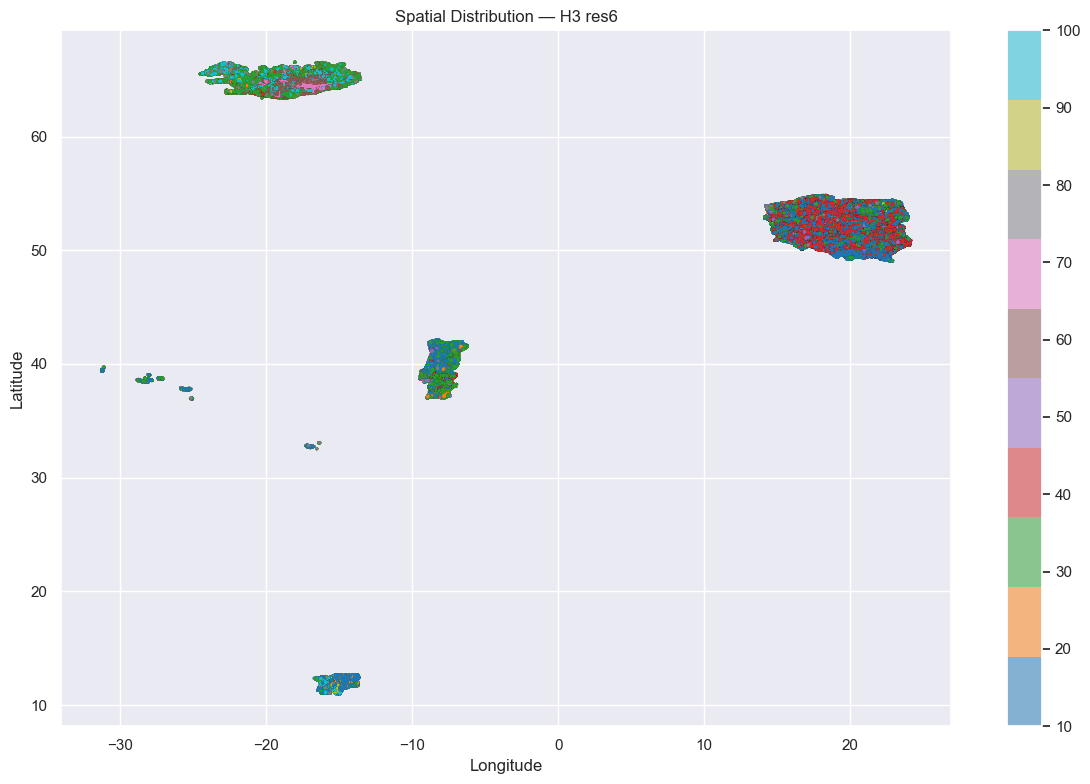

In [21]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df_clean['lon'], 
    df_clean['lat'],
    c=df_clean['label'],
    cmap='tab10',
    s=1,
    alpha=0.5
)
plt.colorbar(scatter)
plt.title('Spatial Distribution — H3 res6')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

label_name
Bare/sparse vegetation    5000
Built-up                  5000
Cropland                  5000
Grassland                 5000
Herbaceous wetland        5000
Mangroves                 5000
Moss and lichen           5000
Permanent water bodies    5000
Shrubland                 5000
Snow and ice              5000
Tree cover                5000
Name: count, dtype: int64
Total: 55000


/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


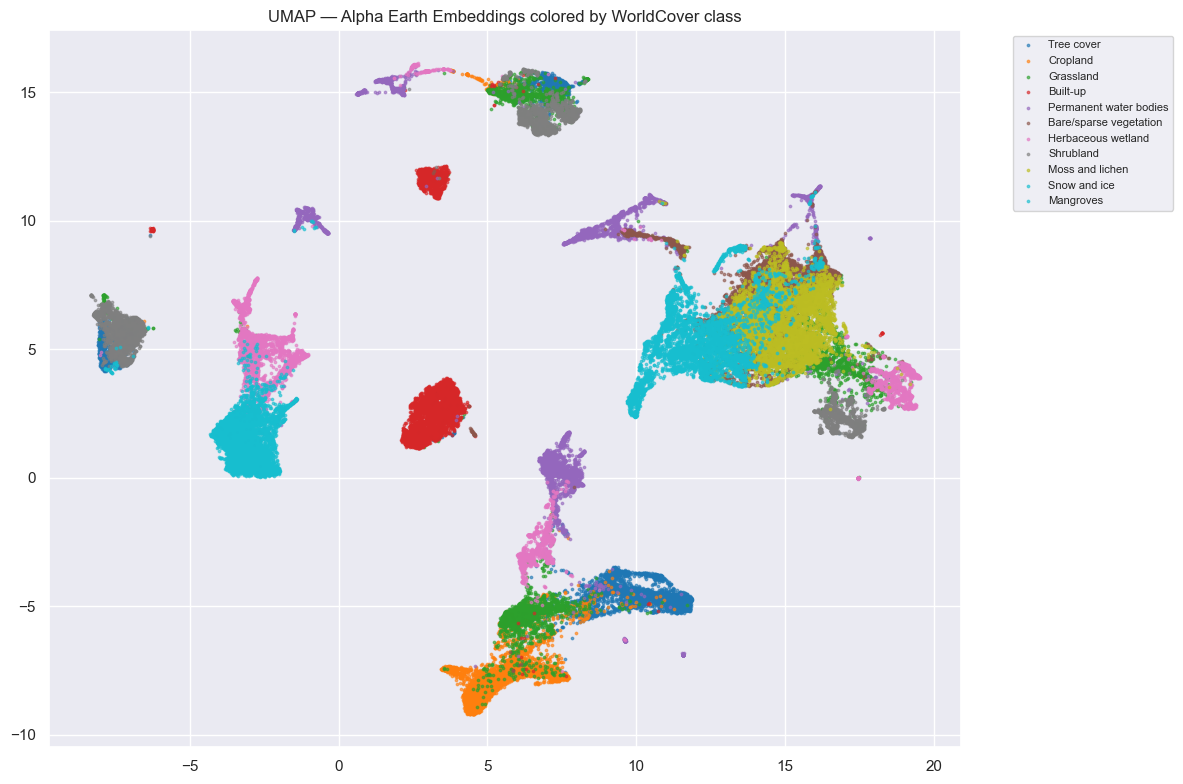

In [22]:
df_sample = df_clean.groupby('label_name', group_keys=False).sample(
    n=5000, replace=True, random_state=42
)

print(df_sample['label_name'].value_counts())
print(f"Total: {len(df_sample)}")

embedding_cols = [c for c in df_sample.columns if c.startswith('A')]
X = df_sample[embedding_cols].values
y = df_sample['label_name'].values

reducer = umap.UMAP(
    random_state=42,
    n_neighbors=15,
    min_dist=0.1,
    low_memory=True
)
embedding_2d = reducer.fit_transform(X)

plt.figure(figsize=(12, 8))
classes = df_clean['label_name'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    mask = y == cls
    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        c=[color],
        label=cls,
        s=3,
        alpha=0.6
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.title('UMAP — Alpha Earth Embeddings colored by WorldCover class')
plt.tight_layout()
plt.show()

In [23]:
print(df_clean[df_clean['label_name'] == 'Bare/sparse vegetation']['homogeneity'].describe())

count    264838.000000
mean          0.913385
std           0.063726
min           0.800007
25%           0.857172
50%           0.915864
75%           0.974745
max           1.000000
Name: homogeneity, dtype: float64


Text(0.5, 1.0, 'PCA — how many dimensions matter?')

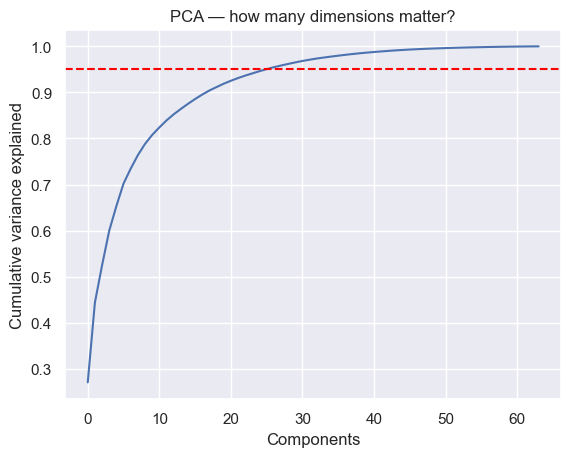

In [24]:
pca = PCA()
pca.fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Components')
plt.ylabel('Cumulative variance explained')
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.title('PCA — how many dimensions matter?')

In [25]:
iso = IsolationForest(contamination=0.02, random_state=42)
outliers = iso.fit_predict(X)
print(f"Outliers detected: {(outliers == -1).sum()}")
df_sample = df_sample[outliers == 1].reset_index(drop=True)

Outliers detected: 1100


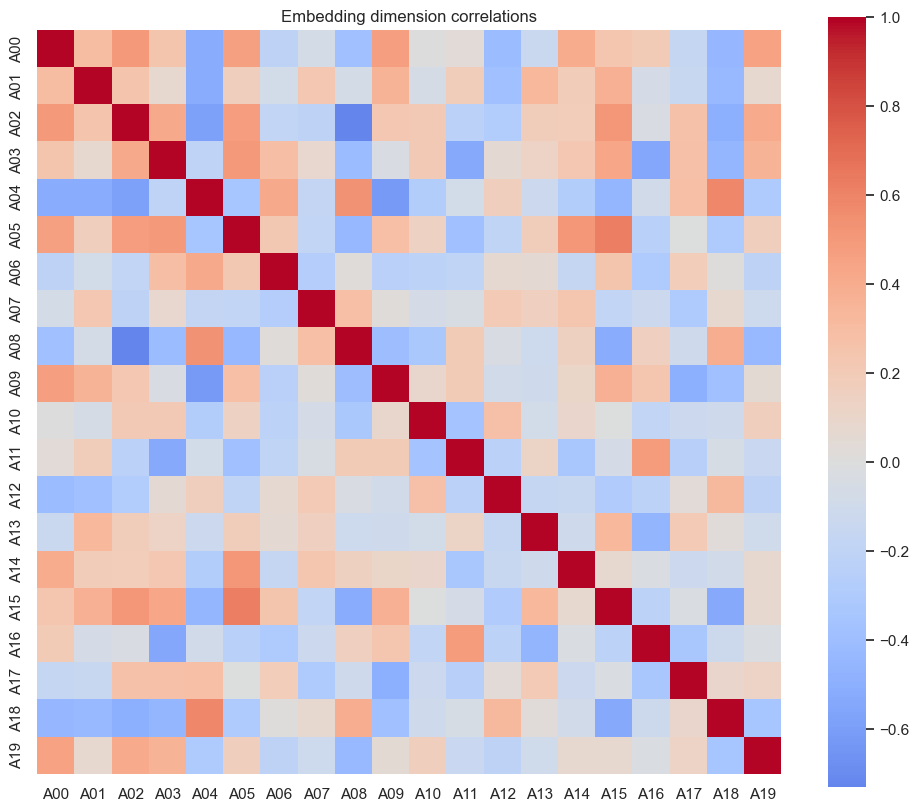

In [26]:
embed_cols = [c for c in df_sample.columns if c.startswith('A')][:20]
X_df = df_sample[embed_cols]
plt.figure(figsize=(12, 10))
sns.heatmap(X_df.corr(), cmap='coolwarm', center=0, square=True)
plt.title('Embedding dimension correlations')
plt.show()

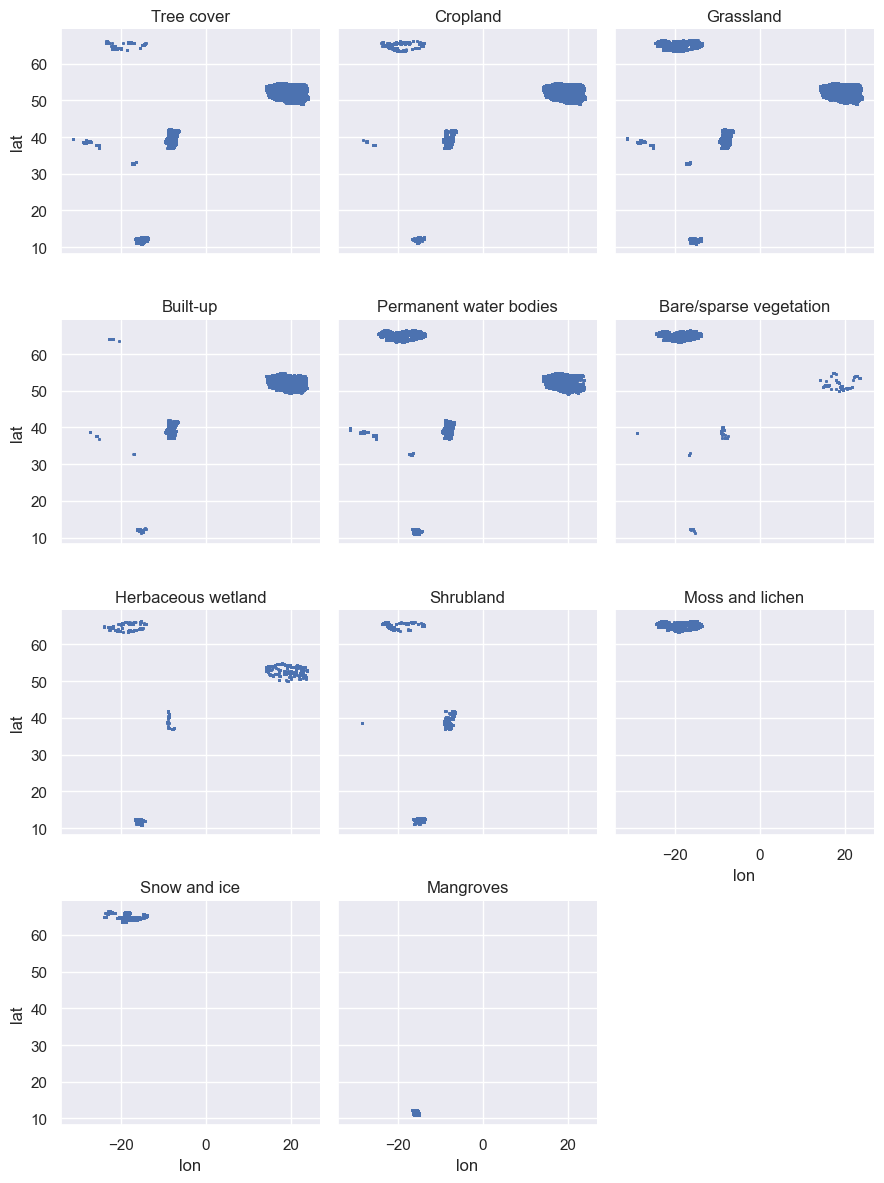

In [27]:
g = sns.FacetGrid(df_clean, col='label_name', col_wrap=3, height=3)
g.map(plt.scatter, 'lon', 'lat', s=1, alpha=0.5)
g.set_titles('{col_name}')
plt.show()

In [28]:
def prepare_ml_dataset(df, min_samples=1000, max_samples=1500, random_state=42):
    """
    Prepare balanced ML-ready dataset from raw embeddings.
    
    Args:
        min_samples: drop classes below this threshold
        max_samples: cap classes above this threshold
        random_state: for reproducibility
    """
    df = df.dropna(subset=['label']).copy()
    
    class_counts = df['label'].value_counts()
    valid = class_counts[class_counts >= min_samples].index
    df = df[df['label'].isin(valid)]
    
    df = df.groupby('label').apply(
        lambda x: x.sample(min(len(x), max_samples), random_state=random_state)
    ).reset_index(drop=True)
    
    print(f"Classes: {df['label_name'].nunique()}")
    print(df['label_name'].value_counts())
    print(f"Total points: {len(df)}")
    
    return df

df_ml = prepare_ml_dataset(df_clean, min_samples=1000, max_samples=2000)

Classes: 11
label_name
Tree cover                2000
Shrubland                 2000
Grassland                 2000
Cropland                  2000
Built-up                  2000
Bare/sparse vegetation    2000
Snow and ice              2000
Permanent water bodies    2000
Herbaceous wetland        2000
Mangroves                 2000
Moss and lichen           2000
Name: count, dtype: int64
Total points: 22000


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

MIN_SAMPLES = 20

embedding_cols = [c for c in df_ml.columns if c.startswith('A')]
X = df_ml[embedding_cols].values
y = df_ml['label_name'].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Classes: {le.classes_}")

Train: (17600, 64), Test: (4400, 64)
Classes: ['Bare/sparse vegetation' 'Built-up' 'Cropland' 'Grassland'
 'Herbaceous wetland' 'Mangroves' 'Moss and lichen'
 'Permanent water bodies' 'Shrubland' 'Snow and ice' 'Tree cover']


In [30]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, 
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, 
        random_state=42, 
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n{name} — Test accuracy: {model.score(X_test, y_test):.3f}")
    print(classification_report(y_test, y_pred, target_names=le.classes_))


Logistic Regression — Test accuracy: 0.897
                        precision    recall  f1-score   support

Bare/sparse vegetation       0.78      0.79      0.78       400
              Built-up       0.99      0.98      0.99       400
              Cropland       0.93      0.93      0.93       400
             Grassland       0.85      0.74      0.79       400
    Herbaceous wetland       0.92      0.91      0.91       400
             Mangroves       0.95      0.98      0.97       400
       Moss and lichen       0.84      0.89      0.86       400
Permanent water bodies       0.94      0.92      0.93       400
             Shrubland       0.86      0.95      0.90       400
          Snow and ice       0.89      0.89      0.89       400
            Tree cover       0.92      0.88      0.90       400

              accuracy                           0.90      4400
             macro avg       0.90      0.90      0.90      4400
          weighted avg       0.90      0.90      0.90     

In [38]:
import ee
import pandas as pd
import sys
sys.path.insert(0, '/Users/pstano/Documents/applications/lucera')

from utilities.grid import KroneckerGridBuilder
from utilities.data_sources import AlphaEarth, ESAWorldCover
from utilities.data_builder import DatasetBuilder
ee.Initialize(project='lucera-494618')

MAZOWIECKIE_BBOX = (19.3, 51.0, 23.0, 53.5)

validation_dataset = (
    DatasetBuilder()
    .from_grid(KroneckerGridBuilder(bbox=MAZOWIECKIE_BBOX, n_points=1000))
    .set_label_source(ESAWorldCover())
    .add_source(AlphaEarth(year=2023))
    .build(strategy='standard')
    .save("data/mazowieckie_validation.csv")
)

Building standard dataset from 1000 points...


Fetching AlphaEarth embeddings: 100%|██████████| 2/2 [00:30<00:00, 15.38s/it]

Dataset built — 1000 rows, 68 columns
Saved to data/mazowieckie_validation.csv


In [ ]:
# df_val = pd.read_csv("data/mazowieckie_validation.csv")
# df_val = df_val.dropna(subset=['label'])

# known_classes = le.classes_
# df_val = df_val[df_val['label_name'].isin(known_classes)]

# embedding_cols = [c for c in df_val.columns if c.startswith('A')]
# X_val = df_val[embedding_cols].values
# y_val = le.transform(df_val['label_name'].values)

# y_pred = models["Random Forest"].predict(X_val)
# print(f"Validation accuracy (Mazowieckie): {(y_pred == y_val).mean():.3f}")
# print(classification_report(y_val, y_pred, target_names=le.classes_))

Validation accuracy (Mazowieckie): 0.854
                        precision    recall  f1-score   support

              Built-up       0.53      0.84      0.65        32
              Cropland       0.82      0.97      0.89       339
             Grassland       0.83      0.69      0.76       241
Permanent water bodies       1.00      1.00      1.00        14
            Tree cover       0.95      0.85      0.90       370

              accuracy                           0.85       996
             macro avg       0.83      0.87      0.84       996
          weighted avg       0.87      0.85      0.85       996

